# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

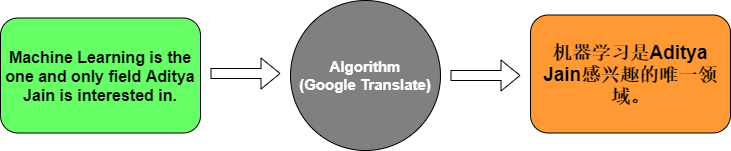

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [ ]:
#!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [ ]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [ ]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [ ]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.1429 - loss: 2.4846 - val_accuracy: 0.0000e+00 - val_loss: 2.4882
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step - accuracy: 0.5714 - loss: 2.4762 - val_accuracy: 0.0000e+00 - val_loss: 2.4898
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.5714 - loss: 2.4675 - val_accuracy: 0.0000e+00 - val_loss: 2.4915
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.5714 - loss: 2.4584 - val_accuracy: 0.0000e+00 - val_loss: 2.4935
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.5714 - loss: 2.4483 - val_accuracy: 0.0000e+00 - val_loss: 2.4958
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step - accuracy: 0.5714 - loss: 2.4370 - val_accuracy: 0.0000e+00 - val_loss: 2.4983
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.5714 - loss: 2.4240 - val_accuracy: 0.0000e+00 - val_loss: 2.5013
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.5714 - loss: 2.4089 - val_acc

In [ ]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. What does the Embedding layer do to a word index?

The Embedding layer converts each word index into a numerical vector that represents the word in a form the model can understand.

2. What is the role of the Encoder LSTM?

The Encoder LSTM reads the input sentence and captures its meaning and context into a representation that is passed to the decoder.

3. What does the Decoder LSTM do?

The Decoder LSTM uses the information from the encoder to generate the translated sentence one word at a time.

4. Why do we use softmax in the final layer?

Softmax converts the model's output into probabilities for each word in the target vocabulary, helping the model choose the most likely next word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [2]:
import sys
!{sys.executable} -m pip install tensorflow

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/351.2 MB 1.2 MB/s eta 0:05:02
   ---------------------------------------- 1.0/351.2 MB 1.5 MB/s eta 0:03:50
   ---------------------------------------- 1.3/351.2 MB 1.5 MB/s eta 0:03:54
   ---------------------------------------- 1.8/351.2 MB 1.7 MB/s eta 0:03:31
   ---------------------------------------- 1.8/351.2 MB 1.7 MB/s eta 0:03:31
   ---------------------------------------- 2.1/351.2 MB 1.5 MB/s eta 0:03:56
   ---------------------------------------- 2.6/351.2 MB 1.6 MB/s eta 0:03:43
   ---------------------------------------- 2.9/351.2 MB 1.5 MB/s eta 0:03:52
   ---------------------------------------- 3.1/351.2 MB 1.5 MB/s eta 0:03:50
   ---------------------------------------- 3.7/351.2 MB 1.5 MB/s eta 0:03:47
   ----

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.45.1 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [6]:

# ==========================================
# Task 2: English-French Machine Translation
# ==========================================

import pandas as pd
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


# 1. Load Dataset
df = pd.read_csv("eng_-french.csv")

df = df[['English words/sentences', 'French words/sentences']]

df = df.dropna().drop_duplicates()

# Use only 5000 sentences
df = df.sample(n=min(5000, len(df)), random_state=42)

english = df.iloc[:, 0].astype(str).str.strip().tolist()
french = df.iloc[:, 1].astype(str).str.strip().tolist()

print("Dataset size:", len(english))


# 2. Add Start and End Tokens
french = ["startseq " + s + " endseq" for s in french]


# 3. Tokenization
eng_tokenizer = Tokenizer()
fr_tokenizer = Tokenizer()

eng_tokenizer.fit_on_texts(english)
fr_tokenizer.fit_on_texts(french)

eng_sequences = eng_tokenizer.texts_to_sequences(english)
fr_sequences = fr_tokenizer.texts_to_sequences(french)


# 4. Padding
MAX_LEN = 15

X = pad_sequences(
    eng_sequences,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

# Decoder input and target
decoder_input = pad_sequences(
    [s[:-1] for s in fr_sequences],
    maxlen=MAX_LEN - 1,
    padding='post',
    truncating='post'
)

decoder_target = pad_sequences(
    [s[1:] for s in fr_sequences],
    maxlen=MAX_LEN - 1,
    padding='post',
    truncating='post'
)

print("English shape:", X.shape)
print("French shape:", decoder_target.shape)


# 5. Build Encoder
encoder_input = tf.keras.layers.Input(shape=(MAX_LEN,))

enc_embedding = tf.keras.layers.Embedding(
    len(eng_tokenizer.word_index) + 1,
    64,
    mask_zero=True
)

enc_lstm = tf.keras.layers.LSTM(
    64,
    return_state=True
)

enc_emb = enc_embedding(encoder_input)

_, state_h, state_c = enc_lstm(enc_emb)

encoder_states = [state_h, state_c]


# 6. Build Decoder
decoder_input_layer = tf.keras.layers.Input(
    shape=(MAX_LEN - 1,)
)

dec_embedding = tf.keras.layers.Embedding(
    len(fr_tokenizer.word_index) + 1,
    64,
    mask_zero=True
)

dec_lstm = tf.keras.layers.LSTM(
    64,
    return_sequences=True,
    return_state=True
)

dec_dense = tf.keras.layers.Dense(
    len(fr_tokenizer.word_index) + 1,
    activation='softmax'
)

dec_emb = dec_embedding(decoder_input_layer)

dec_output, _, _ = dec_lstm(
    dec_emb,
    initial_state=encoder_states
)

output = dec_dense(dec_output)


# 7. Create Training Model
model = tf.keras.Model(
    [encoder_input, decoder_input_layer],
    output
)


# 8. Compile Model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    weighted_metrics=['accuracy']
)


# 9. Train Model
sample_weights = (decoder_target != 0).astype('float32')

history = model.fit(
    [X, decoder_input],
    np.expand_dims(decoder_target, -1),
    sample_weight=sample_weights,
    epochs=3,
    batch_size=32,
    validation_split=0.2
)


# 10. Build Encoder Inference Model
encoder_model = tf.keras.Model(
    encoder_input,
    encoder_states
)


# 11. Build Decoder Inference Model
decoder_token_input = tf.keras.layers.Input(shape=(1,))

decoder_state_h = tf.keras.layers.Input(shape=(64,))
decoder_state_c = tf.keras.layers.Input(shape=(64,))

dec_emb2 = dec_embedding(decoder_token_input)

dec_out2, h2, c2 = dec_lstm(
    dec_emb2,
    initial_state=[decoder_state_h, decoder_state_c]
)

dec_out2 = dec_dense(dec_out2)

decoder_model = tf.keras.Model(
    [decoder_token_input, decoder_state_h, decoder_state_c],
    [dec_out2, h2, c2]
)


# 12. Translation Function
def translate_sentence(sentence):

    sequence = eng_tokenizer.texts_to_sequences([sentence])

    sequence = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding='post',
        truncating='post'
    )

    h, c = encoder_model.predict(sequence, verbose=0)

    start_id = fr_tokenizer.word_index['startseq']
    end_id = fr_tokenizer.word_index['endseq']

    target = np.array([[start_id]])

    translated_words = []

    for _ in range(MAX_LEN - 1):

        prediction, h, c = decoder_model.predict(
            [target, h, c],
            verbose=0
        )

        word_id = int(np.argmax(prediction[0, 0, :]))

        if word_id == end_id or word_id == 0:
            break

        word = fr_tokenizer.index_word.get(word_id)

        if word:
            translated_words.append(word)

        target = np.array([[word_id]])

    return " ".join(translated_words)


# 13. Test Translation
sentence = "How are you?"

translation = translate_sentence(sentence)

print("\nEnglish:", sentence)
print("French:", translation)


Dataset size: 5000
English shape: (5000, 15)
French shape: (5000, 14)
Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step - accuracy: 0.1256 - loss: 6.8007 - val_accuracy: 0.1285 - val_loss: 6.0169
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.1503 - loss: 5.8118 - val_accuracy: 0.1560 - val_loss: 5.8196
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.1562 - loss: 5.6018 - val_accuracy: 0.1681 - val_loss: 5.7398

English: How are you?
French: je
